# Building a Josephson-junction array in qiskit-metal

This notebook builds the series JJ array from `josephson_array_blake.ipynb` as a
single qiskit-metal component, `JosephsonArray`, instead of raw `gdstk` rectangles.

`JosephsonArray` lives in the `qcg-quantum-design` env at
`qiskit_metal/qlibrary/qubits/josephson_array.py` (added alongside `squid_array.py`).
It is the **simulation-oriented** reduction of the Dolan-bridge mask: the
double-angle-evaporation shape of each junction is not what a lumped eigenmode /
LOM solve sees, so each junction is one `pad_gap`-wide vacuum break between two
rectangular islands, bridged by a `junction` `LineString` carrying `L_j` / `C_j`.

* `n_junctions` junctions → `n_junctions + 1` islands, tiled along local x and
  centred on the origin, then moved by `pos_x` / `pos_y` / `orientation`.
* junction `j` bridges islands `j` and `j + 1`; rows are emitted in order
  `jj_0 … jj_{n-1}` so positional addressing (SQDMetal `create_port_JosephsonJunction`)
  works.
* one `ground_gap`-wide `subtract=True` pocket around the whole chain — without it
  the chip-wide ground plane floods every `pad_gap` and shorts every junction.
* `L_j` applies to every junction unless `L_j_overrides = {index: value}` names an
  exception (negative indices count from the end).

In [1]:
from qiskit_metal import designs, MetalGUI

# custom component, lives in the qcg-quantum-design env's qiskit_metal.qlibrary
from qiskit_metal.qlibrary.qubits.josephson_array import JosephsonArray

design = designs.DesignPlanar({}, overwrite_enabled=True)
gui = MetalGUI(design)

05:00PM 01s WARNING [_qt_message_handler]: WARNING: QObject::connect: No such signal QPlatformNativeInterface::systemTrayWindowChanged(QScreen*) (No context available from Qt)
Python Traceback (most recent call last):
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3225, in _run_cell
    result = runner(coro)
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/async_helpers.py", line 128, in _pseudo_sync_runner
    coro.send(None)
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3447, in run_cell_async
    has_raised = await self.run_ast_nodes(code_ast.body, cell_name,
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3688, in run_ast_nodes
    if await self.run_code(code, result, async_=asy):
  File "/home/ruiz/miniconda3/e

05:00PM 01s WARNING [_qt_message_handler]: WARNING: This plugin does not support propagateSizeHints() (No context available from Qt)
Python Traceback (most recent call last):
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3170, in run_cell
    result = self._run_cell(
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3225, in _run_cell
    result = runner(coro)
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/async_helpers.py", line 128, in _pseudo_sync_runner
    coro.send(None)
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3447, in run_cell_async
    has_raised = await self.run_ast_nodes(code_ast.body, cell_name,
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interact

05:00PM 01s WARNING [_qt_message_handler]: WARNING: This plugin does not support propagateSizeHints() (No context available from Qt)
Python Traceback (most recent call last):
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/ipykernel/zmqshell.py", line 549, in run_cell
    return super().run_cell(*args, **kwargs)
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3170, in run_cell
    result = self._run_cell(
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3225, in _run_cell
    result = runner(coro)
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/async_helpers.py", line 128, in _pseudo_sync_runner
    coro.send(None)
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3447, in run_cell_asyn

## Build the array

`n_junctions` is arbitrary. The geometry options below are plain sim islands
(length × width) with a sub-micron `pad_gap` where each junction sits.

In [2]:
N_JUNCTIONS = 40
L_J_NH = 1.2      # inductance of every junction
CJ_J_FF = 2.0     # capacitance of every junction

try:
    array_1.delete()
except NameError:
    pass

array_1 = JosephsonArray(design, 'array_1', options=dict(
    pos_x='0um', pos_y='0um', orientation='0',
    n_junctions=f'{N_JUNCTIONS}',
    pad_length='8um',
    pad_width='6um',
    pad_gap='0.15um',
    jj_width='0.5um',
    L_j=f'{L_J_NH}nH',
    C_j=f'{CJ_J_FF}fF',
    ground_gap='4um',
))

gui.rebuild()
gui.autoscale()

05:00PM 02s WARNING [_qt_message_handler]: WARNING: This plugin does not support propagateSizeHints() (No context available from Qt)
Python Traceback (most recent call last):
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3447, in run_cell_async
    has_raised = await self.run_ast_nodes(code_ast.body, cell_name,
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3688, in run_ast_nodes
    if await self.run_code(code, result, async_=asy):
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3748, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_10937/163305471.py", line 23, in <module>
    gui.autoscale()
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/qiskit_metal/_gui/main_window.py", line 963, in

05:00PM 02s WARNING [_qt_message_handler]: WARNING: This plugin does not support raise() (No context available from Qt)
Python Traceback (most recent call last):
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3688, in run_ast_nodes
    if await self.run_code(code, result, async_=asy):
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3748, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_10937/163305471.py", line 23, in <module>
    gui.autoscale()
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/qiskit_metal/_gui/main_window.py", line 963, in autoscale
    self.plot_win.auto_scale()
  File "/home/ruiz/miniconda3/envs/qcg-quantum-design/lib/python3.11/site-packages/qiskit_metal/_gui/widgets/plot_widget/plot_window.py", line 109, in auto_scale
    self.canvas.auto_sca

## Inspect what was emitted

One `junction` row per junction (`L_j` / `C_j` on every one), `n_junctions + 1`
positive `poly` rows (the islands — `draw.union` of disjoint rectangles splits
into one row each) plus one `subtract=True` ground pocket.

In [3]:
jt = design.qgeometry.tables['junction']
pt = design.qgeometry.tables['poly']

n_islands = (~pt['subtract']).sum()
n_pocket = pt['subtract'].sum()
print(f'junction rows: {len(jt)}  (expect {N_JUNCTIONS})')
print(f'poly rows: {len(pt)}  ({n_islands} islands + {n_pocket} ground pocket)')
print()
print(jt[['name', 'width', 'hfss_inductance', 'hfss_capacitance']].head())
print()
print('pins:', {k: v['middle'].round(4).tolist() for k, v in array_1.pins.items()})

junction rows: 40  (expect 40)
poly rows: 42  (41 islands + 1 ground pocket)

   name   width hfss_inductance hfss_capacitance
0  jj_0  0.0005           1.2nH            2.0fF
1  jj_1  0.0005           1.2nH            2.0fF
2  jj_2  0.0005           1.2nH            2.0fF
3  jj_3  0.0005           1.2nH            2.0fF
4  jj_4  0.0005           1.2nH            2.0fF

pins: {'a': [-0.167, 0.0], 'b': [0.167, 0.0]}


## Per-junction inductance override

`L_j_overrides` (and `C_j_overrides`) is a dict keyed by junction index
(`0 … n_junctions - 1`; negatives count from the end). Here the two end junctions
get a different inductance from the bulk of the array.

In [4]:
array_1.options['L_j_overrides'] = {0: '3nH', -1: '3nH'}
gui.rebuild()

jt = design.qgeometry.tables['junction']
print(jt[['name', 'hfss_inductance']].to_string(index=False))

 name hfss_inductance
 jj_0             3nH
 jj_1           1.2nH
 jj_2           1.2nH
 jj_3           1.2nH
 jj_4           1.2nH
 jj_5           1.2nH
 jj_6           1.2nH
 jj_7           1.2nH
 jj_8           1.2nH
 jj_9           1.2nH
jj_10           1.2nH
jj_11           1.2nH
jj_12           1.2nH
jj_13           1.2nH
jj_14           1.2nH
jj_15           1.2nH
jj_16           1.2nH
jj_17           1.2nH
jj_18           1.2nH
jj_19           1.2nH
jj_20           1.2nH
jj_21           1.2nH
jj_22           1.2nH
jj_23           1.2nH
jj_24           1.2nH
jj_25           1.2nH
jj_26           1.2nH
jj_27           1.2nH
jj_28           1.2nH
jj_29           1.2nH
jj_30           1.2nH
jj_31           1.2nH
jj_32           1.2nH
jj_33           1.2nH
jj_34           1.2nH
jj_35           1.2nH
jj_36           1.2nH
jj_37           1.2nH
jj_38           1.2nH
jj_39             3nH


## Quick matplotlib view (no Qt GUI)

Islands in blue, ground pocket in red, junction bridges in black. With a
sub-micron `pad_gap` the islands look continuous at this zoom — zoom in on one
gap to see the break and its junction line.

In [ ]:
import os
import matplotlib.pyplot as plt
from IPython.display import Image

# qiskit-metal stores geometry in mm; parse_options() has already converted the
# 'um' option strings, so array_1.p.* are in mm.
pitch_mm = array_1.p.pad_length + array_1.p.pad_gap
x_jj = pitch_mm / 2  # first junction right of centre

fig, (ax_all, ax_zoom) = plt.subplots(1, 2, figsize=(13, 3))

for ax in (ax_all, ax_zoom):
    for _, row in design.qgeometry.tables['poly'].iterrows():
        xs, ys = row['geometry'].exterior.xy
        ax.fill(xs, ys, alpha=0.25 if row['subtract'] else 0.8,
                color='red' if row['subtract'] else 'C0')
    for _, row in design.qgeometry.tables['junction'].iterrows():
        xs, ys = row['geometry'].xy
        ax.plot(xs, ys, 'k-', lw=2)
    ax.set_aspect('equal')

ax_all.set_title(f'JosephsonArray  n_junctions={N_JUNCTIONS}')
ax_zoom.set_xlim(x_jj - 0.0015, x_jj + 0.0015)
ax_zoom.set_ylim(-0.005, 0.005)
ax_zoom.set_title('one junction: pad_gap break (white) + junction bridge (black)')

# MetalGUI forces the Qt matplotlib backend, so inline display is unreliable
# under nbconvert -- save and show the PNG instead.
os.makedirs('figures', exist_ok=True)
fig.savefig('figures/josephson_array_preview.png', dpi=110, bbox_inches='tight')
plt.close(fig)
Image('figures/josephson_array_preview.png')

## Open the Qt GUI (optional)

Run this if you want the interactive qiskit-metal window.

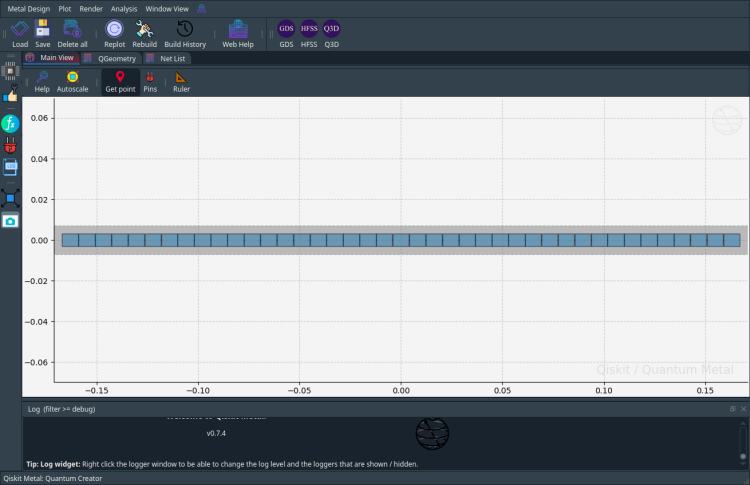

In [6]:
gui.rebuild()
gui.autoscale()
gui.screenshot()